1. IMPORT LIBRARY

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

2. LOAD DATASET

In [25]:
file_path = "dataset/data_clean.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="sampoerna_16"
)

df.head()

,ds,y
0,2023-01-01,30
1,2023-01-02,31
2,2023-01-03,30
3,2023-01-04,33
4,2023-01-05,38


3. PREPRCESSING DATA

In [26]:
#Konversi Tanggal
df['ds'] = pd.to_datetime(df['ds'])

In [27]:
#urutkan data
df = df.sort_values('ds')

In [28]:
#cek missing value
df = df.sort_values('ds')
df = df.dropna()

In [29]:
#cek data duplikat
df.duplicated().sum()

0

In [30]:
#statistik deskriptif
df['y'].describe()

count    1092.000000
mean       20.757326
std         7.066315
min         0.000000
25%        15.000000
50%        20.000000
75%        25.000000
max        61.000000
Name: y, dtype: float64

In [31]:
#jumlah data 0
print(
    "Jumlah data 0:",
    (df['y'] == 0).sum()
)

Jumlah data 0: 5


4. VISUALISASI PENJUALAN

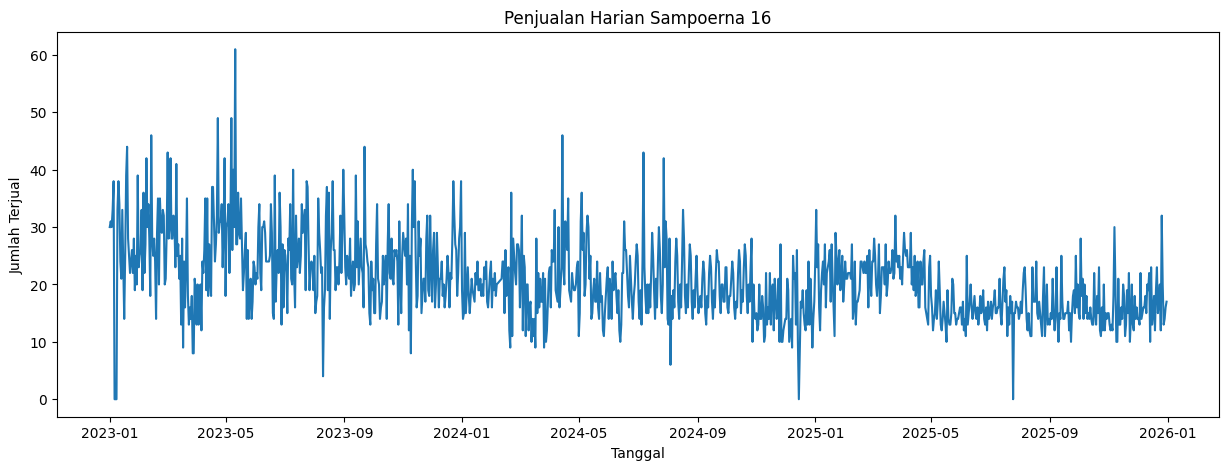

In [32]:
plt.figure(figsize=(15,5))

plt.plot(
    df['ds'],
    df['y']
)

plt.title("Penjualan Harian Sampoerna 16")
plt.xlabel("Tanggal")
plt.ylabel("Jumlah Terjual")

plt.show()

5. ANALISIS PERTAHUN

In [33]:
df['tahun'] = df['ds'].dt.year

df.groupby('tahun')['y'].mean()

tahun
2023    25.046575
2024    19.361878
2025    17.852055
Name: y, dtype: float64

6. SPLIT DATA

In [34]:
train = df[
    df['ds'] < '2025-07-01'
]

test = df[
    df['ds'] >= '2025-07-01'
]

print("Train :", len(train))
print("Test :", len(test))

Train : 908
Test : 184


7. MEMBANGUN MODEL PROPHET

In [35]:
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

model.fit(train)

09:40:24 - cmdstanpy - INFO - Chain [1] start processing
09:40:24 - cmdstanpy - INFO - Chain [1] done processing


8. PREDIKSI DATA TEST

In [36]:
future = model.make_future_dataframe(
    periods=len(test),
    freq='D'
)

forecast = model.predict(future)

In [37]:
#AMBIL PREDIKISI DATA TEST
pred_test = forecast[
    ['ds','yhat']
]

pred_test = pred_test[
    pred_test['ds'].isin(
        test['ds']
    )
]

9. EVALUASI MODEL

In [38]:
evaluation = test.merge(
    pred_test,
    on='ds'
)

In [39]:
mae = mean_absolute_error(
    evaluation['y'],
    evaluation['yhat']
)

rmse = np.sqrt(
    mean_squared_error(
        evaluation['y'],
        evaluation['yhat']
    )
)

smape = np.mean(
    (2 * np.abs(evaluation['y'] - evaluation['yhat']))
    /
    (np.abs(evaluation['y']) + np.abs(evaluation['yhat']))
) * 100

print("MAE :", round(mae))
print("RMSE :", round(rmse))
print("SMAPE :", round(smape,2), "%")

MAE : 4
RMSE : 4
SMAPE : 21.68 %


10. VISUALISASI AKTUAL VS PREDIKSI

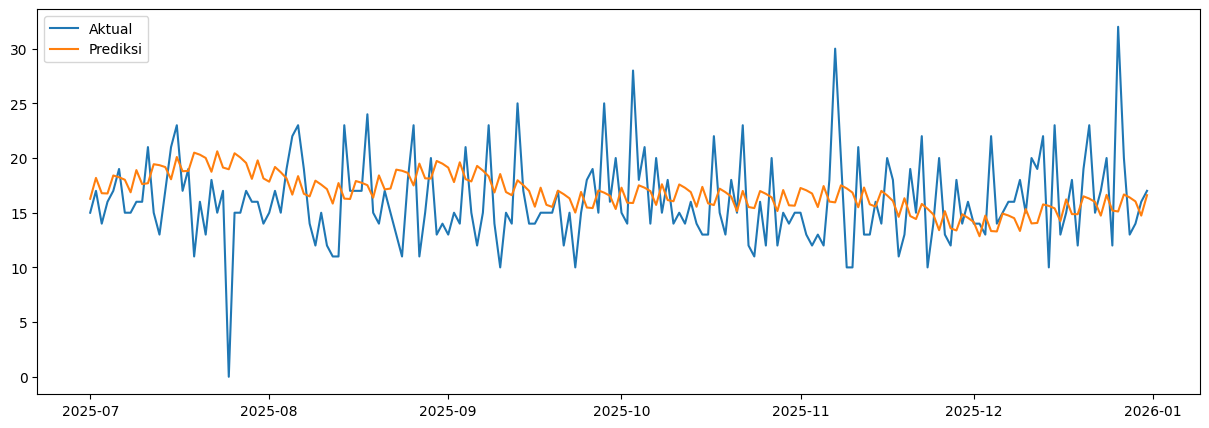

In [40]:
plt.figure(figsize=(15,5))

plt.plot(
    evaluation['ds'],
    evaluation['y'],
    label='Aktual'
)

plt.plot(
    evaluation['ds'],
    evaluation['yhat'],
    label='Prediksi'
)

plt.legend()

plt.show()

11. ANALISIS EROR TERBESAR

In [41]:
evaluation['error'] = abs(
    evaluation['y'] -
    evaluation['yhat']
)

evaluation.sort_values(
    'error',
    ascending=False
).head(20)

,ds,y,tahun,yhat,error
24,2025-07-25,0,2025,18.973524,18.973524
178,2025-12-26,32,2025,15.111980,16.888020
129,2025-11-07,30,2025,15.945001,14.054999
94,2025-10-03,28,2025,15.887132,12.112868
18,2025-07-19,11,2025,20.491252,9.491252
156,2025-12-04,22,2025,13.323593,8.676407
71,2025-09-10,10,2025,18.535396,8.535396
57,2025-08-27,11,2025,19.490482,8.490482
89,2025-09-28,25,2025,16.833320,8.166680
54,2025-08-24,11,2025,18.836397,7.836397


12. TRAINING FINAL MENGGUNAKAN SELURUH DATA

In [42]:
final_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True
)

final_model.fit(df[['ds','y']])

09:40:25 - cmdstanpy - INFO - Chain [1] start processing
09:40:25 - cmdstanpy - INFO - Chain [1] done processing


13. PERAMALAN 14 HARI KEDEPAN

In [43]:
future = final_model.make_future_dataframe(
    periods=14,
    freq='D'
)

forecast = final_model.predict(
    future
)

In [44]:
forecast_14 = forecast[
    ['ds','yhat']
].tail(14)

forecast_14

,ds,yhat
1092,2026-01-01,15.120515
1093,2026-01-02,15.127573
1094,2026-01-03,16.242453
1095,2026-01-04,15.805102
1096,2026-01-05,15.654010
1097,2026-01-06,14.554986
1098,2026-01-07,15.974173
1099,2026-01-08,14.980803
1100,2026-01-09,15.058151
1101,2026-01-10,16.245432


14. HITUNG REKOMENDASI PEMBELIAN

In [45]:
total_forecast = round(
    forecast_14['yhat'].sum()
)

print(
    "Kebutuhan stok 14 hari:",
    total_forecast
)

Kebutuhan stok 14 hari: 217


In [46]:
#TAMBAH SAFETY STOK 10%
stok_beli = round(
    total_forecast * 1.10
)

print(
    "Rekomendasi pembelian:",
    stok_beli
)

Rekomendasi pembelian: 239
